# 01 - Data and EDA

Nigerian Pidgin tweets from AfriSenti (pcm subset), labelled positive / negative / neutral.
In this notebook I load the data, look at it, check quality problems, clean it and save the
versions used by the other notebooks.

In [1]:
import os
import sys
import collections

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../src")
from download_data import download
from preprocess import load_split, dedupe_train, LABELS

sns.set_theme(style="whitegrid")
FIG_DIR = "../results/figures"
os.makedirs(FIG_DIR, exist_ok=True)

download()
train = load_split("../data/raw/train.tsv")
dev = load_split("../data/raw/dev.tsv")
test = load_split("../data/raw/test.tsv")
train.head()

train.tsv already there, skipping
dev.tsv already there, skipping
test.tsv already there, skipping


,tweet,label,text
0,yeah ‍️the guy wants to trend dat was why e jo...,negative,yeah the guy wants to trend dat was why e join...
1,this life is so funny sef you will work hard a...,negative,this life is so funny sef you will work hard a...
2,dis is unfair of urcompany goingtowks nw ive b...,negative,dis is unfair of urcompany goingtowks nw ive b...
3,lil wayne don vex me im actually not excited a...,negative,lil wayne don vex me im actually not excited a...
4,dis is unfair of ur company going to wks nw iv...,negative,dis is unfair of ur company going to wks nw iv...


## Size and label distribution

In [2]:
splits = {"train": train, "dev": dev, "test": test}
rows = []
for name, df in splits.items():
    counts = df["label"].value_counts()
    rows.append({"split": name, "tweets": len(df), **{l: counts.get(l, 0) for l in LABELS}})
sizes = pd.DataFrame(rows).set_index("split")
sizes

,tweets,negative,neutral,positive
split,,,,
train,5121,3241,72,1808
dev,1281,813,21,447
test,4154,2326,431,1397


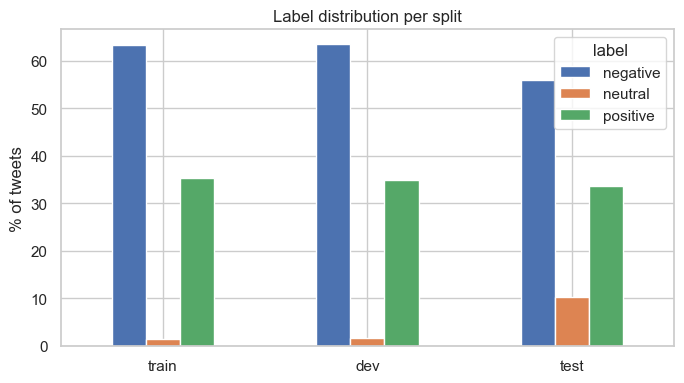

,train,dev,test
label,,,
negative,63.3,63.5,56.0
neutral,1.4,1.6,10.4
positive,35.3,34.9,33.6


In [3]:
# percentages per split, this is where the neutral problem shows
dist = pd.concat({name: df["label"].value_counts(normalize=True) for name, df in splits.items()}, axis=1)
dist = dist.loc[LABELS] * 100

dist.T.plot(kind="bar", figsize=(7, 4))
plt.ylabel("% of tweets")
plt.title("Label distribution per split")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/label_distribution.png", dpi=150)
plt.show()
dist.round(1)

Neutral is only about 1.4% of train but about 10% of test. The model will barely see neutral
during training, so I expect it to struggle with that class. This is also why accuracy alone is not
enough and I use macro-F1.

## Tweet length

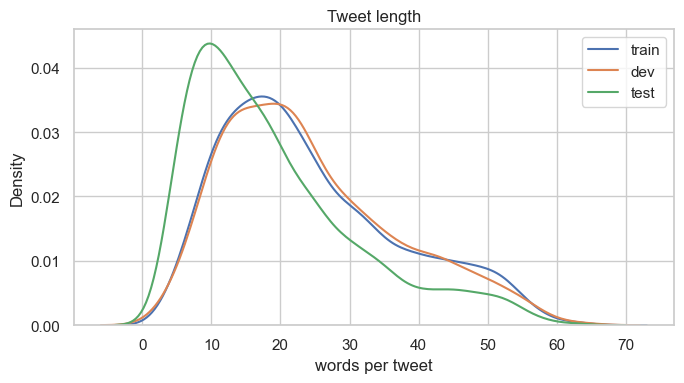

,train,dev,test
count,5121.0,1281.0,4154.0
mean,24.4,24.4,19.0
std,12.9,12.6,12.2
min,3.0,3.0,3.0
25%,14.0,15.0,10.0
50%,21.0,22.0,16.0
75%,32.0,32.0,25.0
max,66.0,63.0,63.0


In [4]:
for df in splits.values():
    df["n_words"] = df["text"].str.split().str.len()

plt.figure(figsize=(7, 4))
for name, df in splits.items():
    sns.kdeplot(df["n_words"], label=name)
plt.xlabel("words per tweet")
plt.legend()
plt.title("Tweet length")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/tweet_length.png", dpi=150)
plt.show()
pd.DataFrame({name: df["n_words"].describe() for name, df in splits.items()}).round(1)

Tweets are short (around 20 words), so a max length of 64 tokens for the models should cover
almost everything. Test tweets are a bit shorter than train.

## Duplicates and overlap between splits

In [5]:
train_texts = set(train["text"])
print("duplicates inside train:", train["text"].duplicated().sum())
print("duplicates inside dev:", dev["text"].duplicated().sum())
print("dev tweets also in train:", dev["text"].isin(train_texts).sum())
print("test tweets also in train:", test["text"].isin(train_texts).sum(), "of", len(test))

duplicates inside train: 513
duplicates inside dev: 34
dev tweets also in train: 258
test tweets also in train: 926 of 4154


In [6]:
# when a test tweet is also in train, do they have the same label?
overlap = test[test["text"].isin(train_texts)].merge(
    train.drop_duplicates("text")[["text", "label"]], on="text", suffixes=("_test", "_train"))
print("same label:", round((overlap["label_test"] == overlap["label_train"]).mean() * 100, 1), "%")
overlap[overlap["label_test"] != overlap["label_train"]][["text", "label_train", "label_test"]].head(10)

same label: 87.8 %


,text,label_train,label_test
15,and then you go ahead and fuck him because the...,negative,positive
16,abeg come and buy na i sell laptops and phones...,negative,positive
19,i get wise friends abeg ola told me something ...,negative,positive
26,if you love rap song go and listen to ft erigg...,negative,positive
28,today marks one small milestone in the beautif...,negative,positive
34,na dream shank just followed me im so emotiona...,neutral,positive
40,lmafoo na why i dey always use good morningeve...,negative,positive
54,body hot like rihana na na kimani kill e show ...,negative,positive
59,lmao na law school abeg we don get marriage or...,negative,positive
60,come be now wey i do see woman wey i love abeg o,negative,positive


About 22% of the official test set is copied word for word from train. A model can just remember
those, so the official test score will look better than it really is. Some copies even have different
labels, which shows label noise.

What I do about it:
- **train**: drop exact duplicates, and drop tweets that appear with conflicting labels
- **dev**: drop tweets that are also in train, so tuning is honest
- **test**: keep the official test (to compare with the AfriSenti paper) and also make a
  **clean test** with the tweets that are not in train. I report both.

## Spelling variation

In [7]:
words = collections.Counter(" ".join(train["text"]).split())
variants = [["dey", "de", "dy"], ["this", "dis"], ["the", "d", "di"], ["wetin", "wettin", "wat"],
            ["abeg", "abegi"], ["dem", "them"], ["una", "una's"]]
pd.DataFrame([{"word": " / ".join(v), "counts": " / ".join(str(words[w]) for w in v)} for v in variants])

,word,counts
0,dey / de / dy,4427 / 353 / 28
1,this / dis,1466 / 307
2,the / d / di,1782 / 243 / 22
3,wetin / wettin / wat,429 / 2 / 9
4,abeg / abegi,500 / 3
5,dem / them,773 / 360
6,una / una's,853 / 0


In [8]:
print("vocabulary size (unique words in train):", len(words))
print("words that appear only once:", sum(1 for w in words.values() if w == 1))
words.most_common(25)

vocabulary size (unique words in train): 10388
words that appear only once: 5371


[('dey', 4427),
 ('i', 3583),
 ('na', 2656),
 ('you', 2173),
 ('me', 1879),
 ('no', 1876),
 ('for', 1825),
 ('the', 1782),
 ('to', 1652),
 ('go', 1573),
 ('like', 1504),
 ('this', 1466),
 ('my', 1449),
 ('e', 1385),
 ('and', 1383),
 ('don', 1309),
 ('be', 1166),
 ('wey', 1117),
 ('say', 1042),
 ('una', 853),
 ('we', 787),
 ('dem', 773),
 ('make', 770),
 ('of', 746),
 ('am', 718)]

The same word is spelled many ways (dey/de/dy, this/dis) and many words appear only once. A word
level model treats each spelling as a totally different word, so I will also try character n-grams,
which can see that "dis" and "this" share letters.

## A few examples per class

In [9]:
pd.set_option("display.max_colwidth", 150)
for label in LABELS:
    print(f"--- {label} ---")
    for t in train[train["label"] == label]["text"].sample(4, random_state=42):
        print("  ", t)

--- negative ---
   they should stop abeg na me dey suffer am
   belle dey pain me breast dey pain me on top this fruit wey eve chop
   onye ela dey there na poverty go cripple u dia hehehe
   me i don send out deliveries already i dey bed dey enjoy ac come let me employ you to be frying puff puff
--- neutral ---
   don don don don foxy i remember when we used to call him sango afolabi sha has to do thanksgiving for his glow up tbh
   phew im getting this if to say you still dey there na you for run this one come oh like the last one thanks once again
   well sha lagos na wah who de cry de see road
   david tar who be dat no be me dey pay am wetin you dey talk sef na me dey pay am so therefore what is his is mine joab big bros i no go advice you make you near there leave mata for matthias you know as e dey be david you wan die
--- positive ---
   i never ask anything from you im a titan im not good and im dry please bless me anyhow my queen even if na small i just want to have the mout

## Clean and save

In [10]:
train_clean, n_conflict = dedupe_train(train)
print("tweets with conflicting labels dropped:", n_conflict)
print("train:", len(train), "->", len(train_clean))

dev_clean = dev[~dev["text"].isin(set(train["text"]))].drop_duplicates("text").reset_index(drop=True)
print("dev:", len(dev), "->", len(dev_clean))

test_clean = test[~test["text"].isin(set(train["text"]))].reset_index(drop=True)
print("test official:", len(test), "| test clean:", len(test_clean))
test_clean["label"].value_counts()

tweets with conflicting labels dropped: 31
train: 5121 -> 4577
dev: 1281 -> 996
test official: 4154 | test clean: 3228


label
negative    1708
positive    1091
neutral      429
Name: count, dtype: int64

In [11]:
os.makedirs("../data/processed", exist_ok=True)
cols = ["text", "label"]
train_clean[cols].to_csv("../data/processed/train.csv", index=False)
dev_clean[cols].to_csv("../data/processed/dev.csv", index=False)
test[cols].to_csv("../data/processed/test_official.csv", index=False)
test_clean[cols].to_csv("../data/processed/test_clean.csv", index=False)
print("saved to data/processed")

saved to data/processed
